# Gaia DR3 Variable Stars: Data Audit and Exploratory Analysis

## Imports and Configuration

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from astropy.timeseries import LombScargle
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from gaia_variable_stars.config import SOURCE_FILE, PHOTOMETRY_FILE, CLEAN_FILE, FIGURES_ROOT, CLASSES, MIN_POINTS, SEED
from gaia_variable_stars.dataset import clean, label

FIGURES_ROOT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)

MIN_PERIOD = 0.1
MAX_PERIOD = 1000.0
TOLERANCE = 0.10
MAX_DRIFT = 0.25

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


In [2]:
sources = pd.read_csv(SOURCE_FILE)
photometry = pd.read_csv(PHOTOMETRY_FILE, dtype={"transit_id": "string"})

if "band" in photometry:
    photometry = photometry.loc[photometry["band"].astype("string").str.upper().eq("G")].copy()
    photometry = photometry.rename(columns={
        "time": "g_transit_time", "mag": "g_transit_mag", "flux": "g_transit_flux",
        "flux_error": "g_transit_flux_error", "n_obs": "g_transit_n_obs",
        "rejected_by_variability": "variability_flag_g_reject"
    })

## Data Overview

### Schema and Source Integrity

In [3]:
source_cols = [
    "source_id", "class_name", "gaia_period", "gaia_period_origin",
    "ecl_lon", "ecl_lat", "bp_rp_color", "g_mean_magnitude", "n_g_epochs"
]

photometry_cols = [
    "source_id", "transit_id", "g_transit_time", "g_transit_mag",
    "g_transit_flux", "g_transit_flux_error", "variability_flag_g_reject"
]

assert set(source_cols).issubset(sources.columns), f"Missing source fields: {set(source_cols) - set(sources)}"
assert set(photometry_cols).issubset(photometry.columns), f"Missing photometry fields: {set(photometry_cols) - set(photometry)}"
assert sources["source_id"].is_unique and sources["class_name"].isin(CLASSES).all()
assert photometry["source_id"].isin(sources["source_id"]).all()

labeled = label(sources, photometry)

print("Sources:", len(sources))
print("Photometry:", len(photometry))

Sources: 2000
Photometry: 90126


In [4]:
display(sources["class_name"].value_counts().reindex(CLASSES, fill_value=0).to_frame("stars"))
display(sources.head(3))

,stars
class_name,
RR Lyrae,500
Cepheid,500
Eclipsing Binary,500
Long-Period Variable,500


,source_id,random_index,ra,dec,ecl_lon,ecl_lat,g_mean_magnitude,bp_mean_magnitude,rp_mean_magnitude,bp_rp_color,gaia_pf,gaia_p1_o,class_name,gaia_p2_o,gaia_frequency,gaia_period,gaia_period_origin,n_g_epochs
0,245251978451433728,1520826064,56.420114,46.682834,65.001881,26.115460,18.876387,19.333345,18.299236,1.034109,NaN,0.337184,RR Lyrae,NaN,NaN,0.337184,p1_o,37
1,5712669411241837184,1286622709,117.543461,-20.286212,124.754685,-40.459960,17.915445,18.395552,17.215742,1.179810,0.626575,NaN,RR Lyrae,NaN,NaN,0.626575,pf,45
2,5862160287770085632,343164423,198.333702,-63.766373,229.098839,-50.145385,20.633400,22.233725,19.275316,2.958408,0.637236,NaN,RR Lyrae,NaN,NaN,0.637236,pf,24


### Observation Quality Check

In [5]:
checks = labeled.copy()

for col in ["g_transit_time", "g_transit_mag", "g_transit_flux", "g_transit_flux_error"]:
    checks[col] = pd.to_numeric(checks[col], errors="coerce")

flag = checks["variability_flag_g_reject"].astype("string").str.strip().str.lower()

checks["missing_id"] = checks["transit_id"].isna()
checks["duplicate_id"] = checks["transit_id"].notna() & checks.duplicated(["source_id", "transit_id"], keep=False)
checks["duplicate_time"] = checks.duplicated(["source_id", "g_transit_time"], keep=False)
checks["invalid_time"] = ~np.isfinite(checks["g_transit_time"])
checks["invalid_magnitude"] = ~np.isfinite(checks["g_transit_mag"])
checks["invalid_flux"] = checks["g_transit_flux"].notna() & (~np.isfinite(checks["g_transit_flux"]) | checks["g_transit_flux"].le(0))
checks["missing_flux"] = checks["g_transit_flux"].isna()
checks["invalid_error"] = ~np.isfinite(checks["g_transit_flux_error"]) | checks["g_transit_flux_error"].le(0)
checks["unknown_flag"] = ~flag.isin(["true", "false", "1", "0", "1.0", "0.0", "t", "f"])
checks["rejected"] = flag.isin(["true", "1", "1.0", "t"])

issue_cols = [
    "missing_id", "duplicate_id", "duplicate_time", "invalid_time",
    "invalid_magnitude", "invalid_flux", "missing_flux", "invalid_error",
    "unknown_flag", "rejected"
]

issues = checks.groupby(["class_name", "source_id"])[issue_cols].any()
issues = issues.groupby("class_name").sum().reindex(CLASSES, fill_value=0)

display(issues.astype(int))

,missing_id,duplicate_id,duplicate_time,invalid_time,invalid_magnitude,invalid_flux,missing_flux,invalid_error,unknown_flag,rejected
class_name,,,,,,,,,,
RR Lyrae,0,0,56,175,175,0,175,175,0,333
Cepheid,0,0,175,350,350,0,350,350,0,444
Eclipsing Binary,0,0,105,257,257,0,257,257,0,399
Long-Period Variable,0,0,133,316,316,0,316,316,0,358


In [6]:
cleaned = clean(labeled)
retained = labeled.index.isin(cleaned.index)

print("Clean Observations:", len(cleaned))
print("Removed Observations:", len(labeled) - len(cleaned))

counts = pd.DataFrame({
    "raw": labeled.groupby("class_name").size(),
    "clean": cleaned.groupby("class_name").size()
})

display(counts.reindex(CLASSES).fillna(0).astype(int))

Clean Observations: 85243
Removed Observations: 4883


,raw,clean
class_name,,
RR Lyrae,20800,20010
Cepheid,23439,21672
Eclipsing Binary,22884,21685
Long-Period Variable,23003,21876


### Cleaning Consistency

In [7]:
# if CLEAN_FILE.exists():
saved = pd.read_csv(CLEAN_FILE, dtype={"transit_id": "string"})

cols = [
    col for col in [
        "source_id", "transit_id", "g_transit_time", "g_transit_mag",
        "g_transit_flux", "g_transit_flux_error"
    ] if col in saved and col in cleaned
]

sort_cols = [col for col in ["source_id", "g_transit_time", "transit_id"] if col in cols]

left = saved[cols].sort_values(sort_cols, na_position="last").reset_index(drop=True)
right = cleaned[cols].sort_values(sort_cols, na_position="last").reset_index(drop=True)

pd.testing.assert_frame_equal(left, right, check_dtype=False, rtol=1e-8, atol=1e-8)

print("Saved Cleaning Matches:", True)
print("Saved Observations:", len(saved))

Saved Cleaning Matches: True
Saved Observations: 85243


In [8]:
counts = cleaned.groupby("source_id").size().reindex(sources["source_id"], fill_value=0)
changed = sources["n_g_epochs"].ne(counts.to_numpy()).sum()

print("Changed Epoch Counts:", int(changed))

Changed Epoch Counts: 0


### Missingness and Period Origins

In [9]:
observed_cols = ["gaia_period", "ecl_lat", "g_mean_magnitude", "bp_rp_color"]
obs_cols = ["g_transit_time", "g_transit_mag", "g_transit_flux", "g_transit_flux_error"]

source_missing = sources.groupby("class_name")[observed_cols].agg(lambda x: x.isna().mean() * 100)
obs_missing = labeled.groupby("class_name")[obs_cols].agg(lambda x: x.isna().mean() * 100)

display(source_missing.reindex(CLASSES).round(2))
display(obs_missing.reindex(CLASSES).round(2))
display(pd.crosstab(sources["class_name"], sources["gaia_period_origin"]).reindex(CLASSES, fill_value=0))

,gaia_period,ecl_lat,g_mean_magnitude,bp_rp_color
class_name,,,,
RR Lyrae,0.0,0.0,0.0,7.4
Cepheid,0.0,0.0,0.0,0.0
Eclipsing Binary,0.0,0.0,0.0,0.8
Long-Period Variable,0.0,0.0,0.0,0.0


,g_transit_time,g_transit_mag,g_transit_flux,g_transit_flux_error
class_name,,,,
RR Lyrae,1.31,1.31,1.31,1.31
Cepheid,2.52,2.52,2.52,2.52
Eclipsing Binary,1.78,1.78,1.78,1.78
Long-Period Variable,2.14,2.14,2.14,2.14


gaia_period_origin,frequency,p1_o,pf
class_name,,,
RR Lyrae,0,188,312
Cepheid,0,193,307
Eclipsing Binary,500,0,0
Long-Period Variable,500,0,0


In [10]:
period_coverage = (sources.groupby("class_name")
                   .agg(stars=("source_id", "size"),
                        published_periods=("gaia_period", lambda value: value.gt(0).sum()),
                        median_period=("gaia_period", "median")).reindex(CLASSES)
                   )

period_coverage["selected_coverage_pct"] = 100 * period_coverage["published_periods"] / period_coverage["stars"]

display(period_coverage.round(2))

,stars,published_periods,median_period,selected_coverage_pct
class_name,,,,
RR Lyrae,500,500,0.48,100.0
Cepheid,500,500,3.15,100.0
Eclipsing Binary,500,500,0.42,100.0
Long-Period Variable,500,500,249.13,100.0


## Photometric Precision

In [11]:
quality = checks
quality["retained"] = retained

valid_error = (
    np.isfinite(quality["g_transit_flux"]) & quality["g_transit_flux"].gt(0)
    & np.isfinite(quality["g_transit_flux_error"]) & quality["g_transit_flux_error"].gt(0)
)

quality["relative_error"] = (quality["g_transit_flux_error"] / quality["g_transit_flux"]).where(valid_error)
quality["magnitude_error"] = 1.0857 * quality["relative_error"]

if "g_transit_n_obs" in labeled:
    quality["g_transit_n_obs"] = pd.to_numeric(labeled["g_transit_n_obs"], errors="coerce")

for col in ["variability_flag_g_reject", "photometry_flag_noisy_data"]:
    if col in labeled:
        states = labeled[col].astype("string").str.lower().fillna("missing")
        display(pd.crosstab(
            [labeled["class_name"], states], retained,
            rownames=["class", col], colnames=["retained"]
        ))
    elif col == "photometry_flag_noisy_data" and "other_flags" in labeled:
        print("Noisy Flag: Encoded in other_flags; not decoded.")

retained                                        False  True 
class                variability_flag_g_reject              
Cepheid              false                          0  21672
                     true                        1767      0
Eclipsing Binary     false                          0  21685
                     true                        1199      0
Long-Period Variable false                          0  21876
                     true                        1127      0
RR Lyrae             false                          0  20010
                     true                         790      0

In [12]:
summary_cols = ["g_transit_flux_error", "relative_error", "magnitude_error"]
if "g_transit_n_obs" in quality:
    summary_cols.append("g_transit_n_obs")

display(quality.groupby(["class_name", "retained"])[summary_cols].agg(["count", "median"]).round(4))

g_transit_flux_error          relative_error  \
                                             count   median          count   
class_name           retained                                                
Cepheid              False                    1176  28.7663           1176   
                     True                    21672  23.1242          21672   
Eclipsing Binary     False                     792  41.9841            792   
                     True                    21685   9.3836          21685   
Long-Period Variable False                     634  59.3107            634   
                     True                    21876  67.6062          21876   
RR Lyrae             False                     518  25.2688            518   
                     True                    20010  10.8334          20010   

                                      magnitude_error          
                               median           count  median  
class_name           retained                                  
Cepheid              False     0.0036            1176  0.0039  
                     True      0.0022           21672  0.0024  
Eclipsing Binary     False     0.0234             792  0.0254  
                     True      0.0073           21685  0.0079  
Long-Period Variable False     0.0036             634  0.0039  
                     True      0.0023           21876  0.0025  
RR Lyrae             False     0.0379             518  0.0411  
                     True      0.0064           20010  0.0069

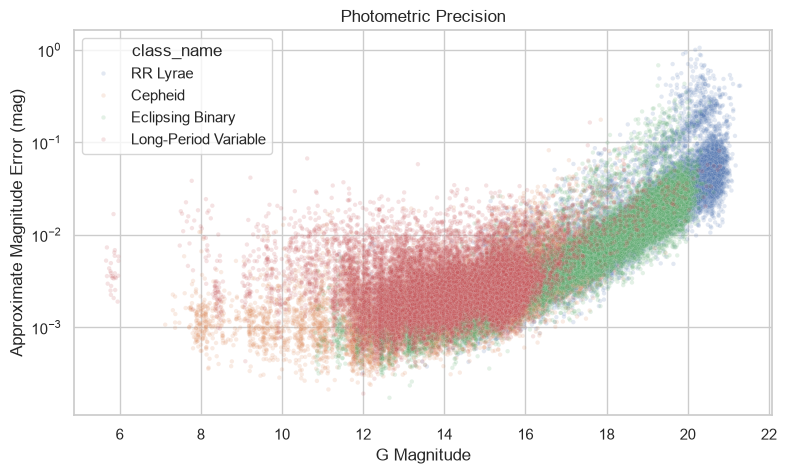

In [13]:
figure, axis = plt.subplots(figsize=(9, 5))

precision = quality.loc[quality["retained"] & quality["magnitude_error"].gt(0)]

sns.scatterplot(data=precision, x="g_transit_mag", y="magnitude_error", hue="class_name", hue_order=CLASSES, alpha=0.16, s=10, ax=axis)
axis.set(yscale="log", xlabel="G Magnitude", ylabel="Approximate Magnitude Error (mag)", title="Photometric Precision")

figure.savefig(FIGURES_ROOT / "01_photometric_precision.png", dpi=160, bbox_inches="tight")
plt.show()

## Star-Level Measurements

In [14]:
obs_cols = [
    "source_id", "g_transit_time", "g_transit_mag",
    "g_transit_flux", "g_transit_flux_error"
]

observations = cleaned[obs_cols].sort_values(["source_id", "g_transit_time"]).copy()

flux = pd.to_numeric(observations["g_transit_flux"], errors="coerce")
error = pd.to_numeric(observations["g_transit_flux_error"], errors="coerce")
valid_error = np.isfinite(flux) & flux.gt(0) & np.isfinite(error) & error.gt(0)

observations["magnitude_error"] = (1.0857 * error / flux).where(valid_error)
observations["time_gap"] = observations.groupby("source_id")["g_transit_time"].diff()
observations["short_gap"] = observations["time_gap"].between(0, 1, inclusive="neither")
observations["long_gap"] = observations["time_gap"].gt(30)
observations["new_group"] = observations["time_gap"].gt(1)

In [15]:
star_stats = observations.groupby("source_id").agg(
    n_epochs=("g_transit_time", "size"),
    time_span=("g_transit_time", lambda x: x.max() - x.min()),
    median_gap=("time_gap", "median"),
    positive_gaps=("time_gap", lambda x: x.gt(0).sum()),
    short_gaps=("short_gap", "sum"),
    long_gaps=("long_gap", "sum"),
    observing_groups=("new_group", lambda x: int(x.sum()) + 1),
    magnitude_mean=("g_transit_mag", "mean"),
    magnitude_std=("g_transit_mag", "std"),
    magnitude_skew=("g_transit_mag", "skew"),
    magnitude_kurt=("g_transit_mag", pd.Series.kurt),
    magnitude_mad=("g_transit_mag", lambda x: (x - x.median()).abs().median()),
    amplitude=("g_transit_mag", lambda x: x.quantile(0.95) - x.quantile(0.05)),
    median_error=("magnitude_error", "median"),
    valid_errors=("magnitude_error", "count")
).reset_index()

In [16]:
stars = sources.merge(star_stats, on="source_id", how="left", validate="one_to_one")

stars["n_epochs"] = stars["n_epochs"].fillna(0).astype(int)
stars["valid_errors"] = stars["valid_errors"].fillna(0).astype(int)
stars["abs_latitude"] = stars["ecl_lat"].abs()
stars["usable"] = stars["n_epochs"].ge(MIN_POINTS)
stars["short_gap_fraction"] = stars["short_gaps"] / stars["positive_gaps"].replace(0, np.nan)
stars["long_gap_fraction"] = stars["long_gaps"] / stars["positive_gaps"].replace(0, np.nan)
stars["amplitude_ratio"] = stars["amplitude"] / stars["median_error"].replace(0, np.nan)
stars["scatter_ratio"] = stars["magnitude_std"] / stars["median_error"].replace(0, np.nan)

print("Star Dataset:", len(stars))

display(
    stars.groupby("class_name")[
        ["n_epochs", "time_span", "median_gap", "amplitude", "median_error", "amplitude_ratio"]
    ].median().reindex(CLASSES).round(3)
)

Star Dataset: 2000


,n_epochs,time_span,median_gap,amplitude,median_error,amplitude_ratio
class_name,,,,,,
RR Lyrae,37.0,933.938,0.375,0.465,0.008,61.988
Cepheid,39.0,979.944,26.996,0.403,0.002,162.329
Eclipsing Binary,40.0,959.394,7.842,0.278,0.009,28.977
Long-Period Variable,42.0,959.343,17.467,0.318,0.002,134.554


### Measurement Bias and Cadence

In [17]:
rr_lyrae = stars.loc[stars["class_name"].eq("RR Lyrae")].copy()
rr_lyrae["missing_color"] = rr_lyrae["bp_rp_color"].isna()

display(
    rr_lyrae.groupby("missing_color")[
        ["g_mean_magnitude", "n_epochs", "median_error", "amplitude"]
    ].agg(["count", "median"]).round(3)
)

display(
    stars.groupby("class_name")[
        ["short_gap_fraction", "long_gap_fraction", "observing_groups", "scatter_ratio"]
    ].median().reindex(CLASSES).round(3)
)

print("Low Signal Stars:", int(stars["amplitude_ratio"].le(3).sum()))
print("High Scatter Stars:", int(stars["scatter_ratio"].gt(10).sum()))

g_mean_magnitude         n_epochs        median_error         \
                         count  median    count median        count median   
missing_color                                                                
False                      463  17.985      463   37.0          463  0.008   
True                        37  20.083       37   32.0           37  0.046   

              amplitude         
                  count median  
missing_color                   
False               463  0.476  
True                 37  0.407

,short_gap_fraction,long_gap_fraction,observing_groups,scatter_ratio
class_name,,,,
RR Lyrae,0.513,0.303,18.0,20.889
Cepheid,0.361,0.402,26.0,57.447
Eclipsing Binary,0.483,0.344,20.0,10.841
Long-Period Variable,0.435,0.333,24.0,44.772


Low Signal Stars: 0
High Scatter Stars: 1569


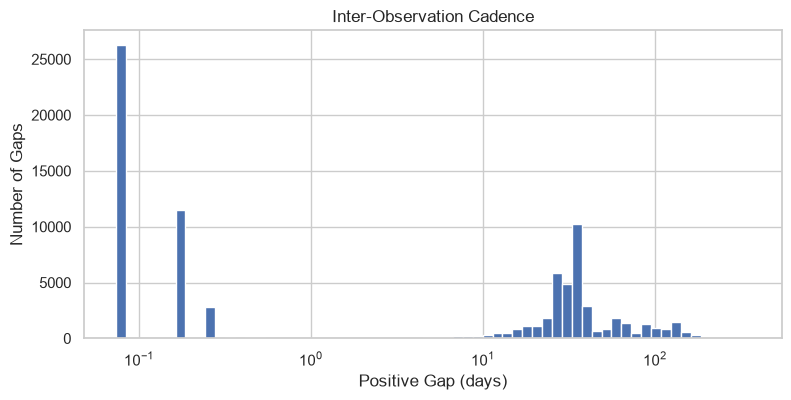

In [18]:
gaps = observations.loc[observations["time_gap"].gt(0), "time_gap"]

figure, axis = plt.subplots(figsize=(9, 4))
if len(gaps):
    axis.hist(gaps, bins=np.geomspace(gaps.min(), gaps.max() * 1.00001, 65))
    axis.set_xscale("log")
axis.set(xlabel="Positive Gap (days)", ylabel="Number of Gaps", title="Inter-Observation Cadence")

figure.savefig(FIGURES_ROOT / "02_observation_gaps.png", dpi=160, bbox_inches="tight")
plt.show()

## Sky Coverage and Sample Selection

In [19]:
stars["latitude_bin"] = pd.cut(stars["abs_latitude"], [0, 15, 30, 45, 60, 75, 90], include_lowest=True)

display(pd.crosstab(stars["class_name"], stars["latitude_bin"]).reindex(CLASSES, fill_value=0))
display(stars.groupby(["class_name", "latitude_bin"], observed=True)[["n_epochs", "median_gap", "short_gap_fraction"]].median().round(2))

latitude_bin,"(-0.001, 15.0]","(15.0, 30.0]","(30.0, 45.0]","(45.0, 60.0]","(60.0, 75.0]","(75.0, 90.0]"
class_name,,,,,,
RR Lyrae,152,106,140,64,22,16
Cepheid,46,19,39,66,25,305
Eclipsing Binary,129,127,0,0,52,192
Long-Period Variable,99,96,53,24,21,207


n_epochs  median_gap  short_gap_fraction
class_name           latitude_bin                                            
Cepheid              (-0.001, 15.0]      30.0       11.46                0.48
                     (15.0, 30.0]        42.0        0.21                0.54
                     (30.0, 45.0]        52.0        0.18                0.59
                     (45.0, 60.0]        53.5       13.82                0.46
                     (60.0, 75.0]        45.0       24.99                0.37
                     (75.0, 90.0]        37.0       28.17                0.32
Eclipsing Binary     (-0.001, 15.0]      44.0        0.18                0.61
                     (15.0, 30.0]        30.0       17.59                0.43
                     (60.0, 75.0]        58.0        0.25                0.54
                     (75.0, 90.0]        41.0       28.49                0.34
Long-Period Variable (-0.001, 15.0]      33.0        0.18                0.56
                     (15.0, 30.0]        47.0        0.18                0.57
                     (30.0, 45.0]        52.0        0.18                0.57
                     (45.0, 60.0]        59.0        0.18                0.52
                     (60.0, 75.0]        47.0       25.75                0.40
                     (75.0, 90.0]        39.0       27.67                0.33
RR Lyrae             (-0.001, 15.0]      35.0        0.21                0.54
                     (15.0, 30.0]        32.0        3.50                0.50
                     (30.0, 45.0]        40.0        0.25                0.52
                     (45.0, 60.0]        49.5       15.86                0.45
                     (60.0, 75.0]        40.5       27.67                0.36
                     (75.0, 90.0]        35.0       28.93                0.32

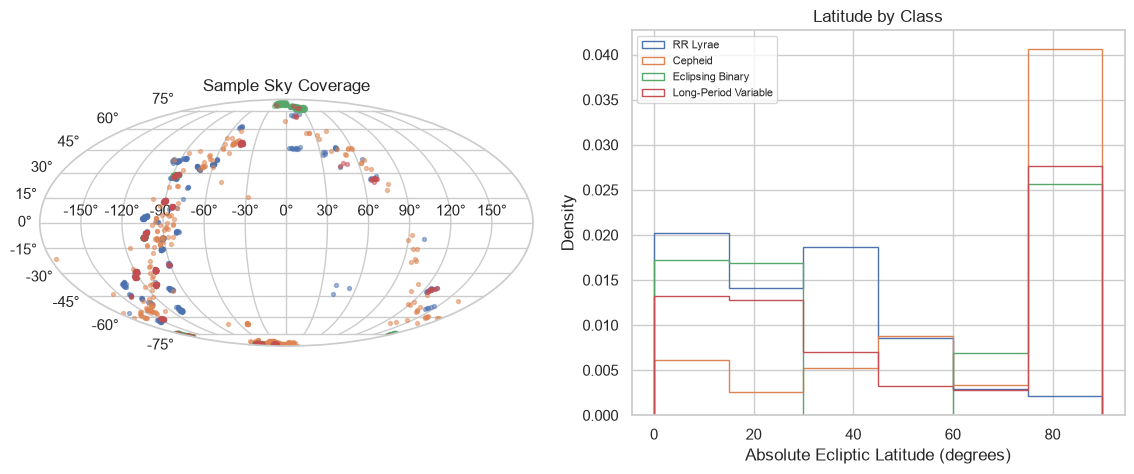

In [20]:
figure = plt.figure(figsize=(14, 5))

sky_axis = figure.add_subplot(121, projection="mollweide")
latitude_axis = figure.add_subplot(122)

for name in CLASSES:
    group = stars.loc[stars["class_name"].eq(name)].dropna(subset=["ecl_lon", "ecl_lat"])
    longitude = (group["ecl_lon"] + 180) % 360 - 180
    sky_axis.scatter(np.radians(longitude), np.radians(group["ecl_lat"]), s=8, alpha=0.5, label=name)
    latitude_axis.hist(group["abs_latitude"].dropna(), bins=[0, 15, 30, 45, 60, 75, 90], density=True, histtype="step", label=name)

sky_axis.set_title("Sample Sky Coverage")
sky_axis.grid(True)

latitude_axis.set(xlabel="Absolute Ecliptic Latitude (degrees)", ylabel="Density", title="Latitude by Class")
latitude_axis.legend(fontsize=8)

figure.savefig(FIGURES_ROOT / "03_sky_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

## Light Curves and Photometric Structure

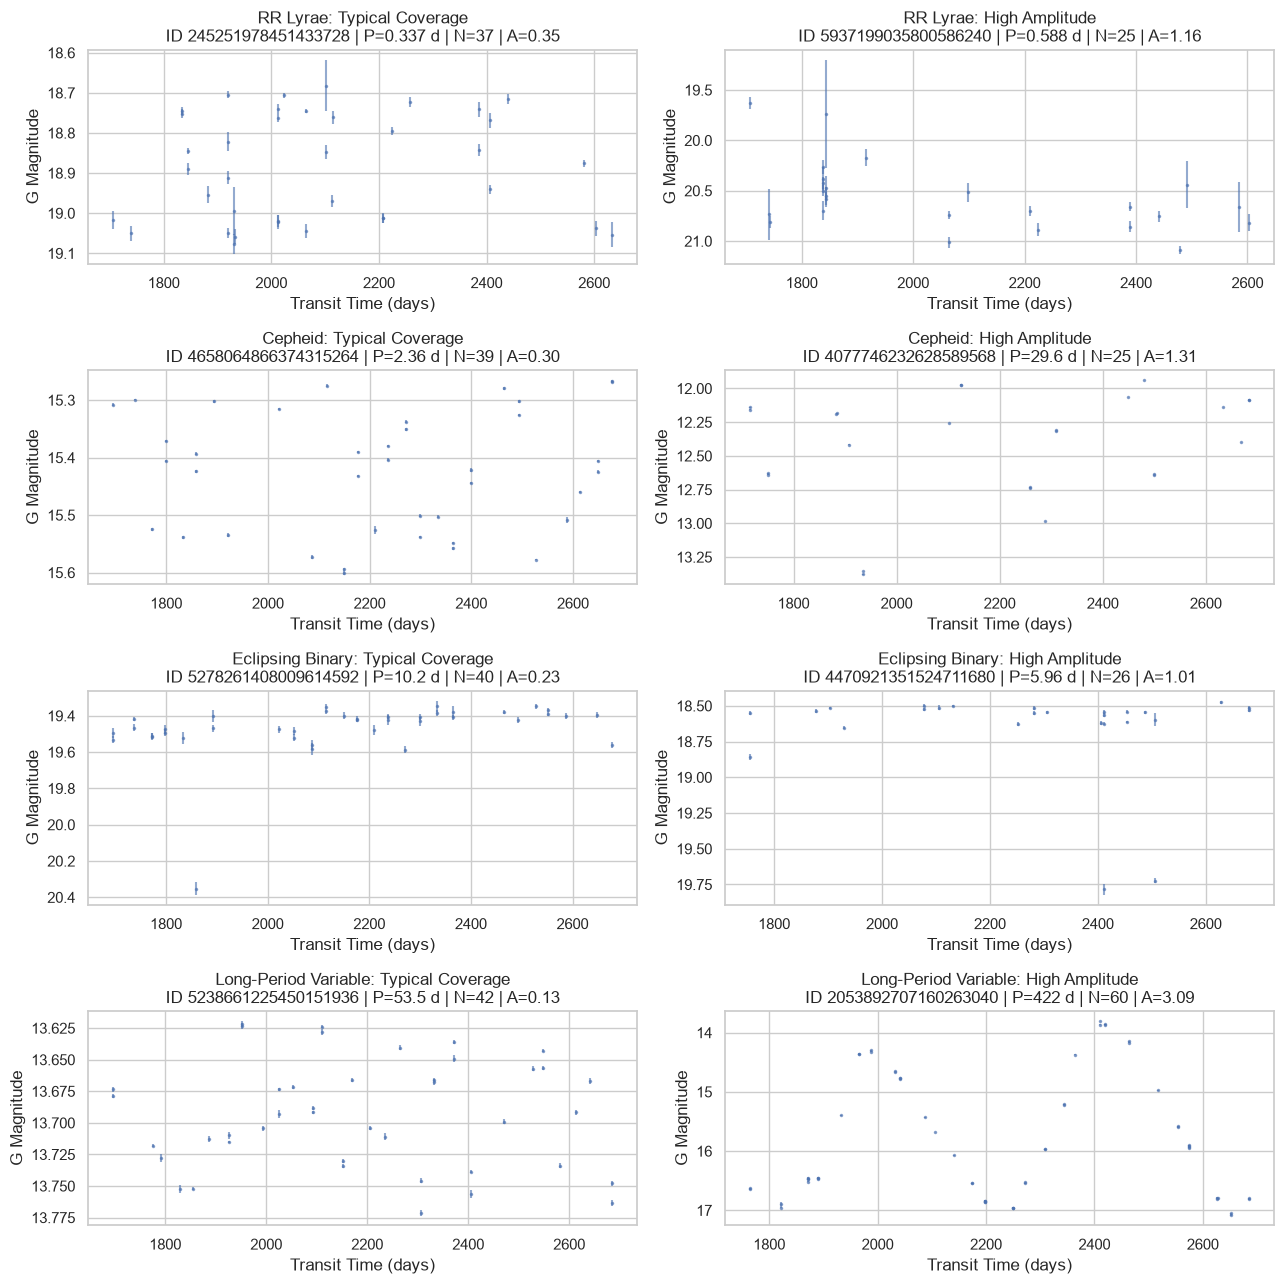

In [21]:
figure, axes = plt.subplots(4, 2, figsize=(13, 13))

for row, name in enumerate(CLASSES):
    group = stars.loc[stars["class_name"].eq(name) & stars["usable"]]

    if group.empty:
        for axis in axes[row]:
            axis.set_visible(False)
        continue

    typical = group.iloc[(group["n_epochs"] - group["n_epochs"].median()).abs().argmin()]
    high = group.loc[group["amplitude"].idxmax()]

    for axis, (label_name, star) in zip(axes[row], [("Typical Coverage", typical), ("High Amplitude", high)]):
        group_obs = observations.loc[observations["source_id"].eq(star["source_id"])]
        valid = group_obs["magnitude_error"].gt(0) & np.isfinite(group_obs["magnitude_error"])

        axis.errorbar(
            group_obs.loc[valid, "g_transit_time"], group_obs.loc[valid, "g_transit_mag"],
            yerr=group_obs.loc[valid, "magnitude_error"], fmt=".", ms=3, alpha=0.6
        )
        axis.scatter(
            group_obs.loc[~valid, "g_transit_time"],
            group_obs.loc[~valid, "g_transit_mag"], s=10
        )
        axis.invert_yaxis()
        axis.set(
            title=f"{name}: {label_name}\nID {int(star['source_id'])} | P={star['gaia_period']:.3g} d | N={star['n_epochs']} | A={star['amplitude']:.2f}",
            xlabel="Transit Time (days)", ylabel="G Magnitude"
        )

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "04_light_curves.png", dpi=160, bbox_inches="tight")
plt.show()

### Period–Amplitude and Color Relationships

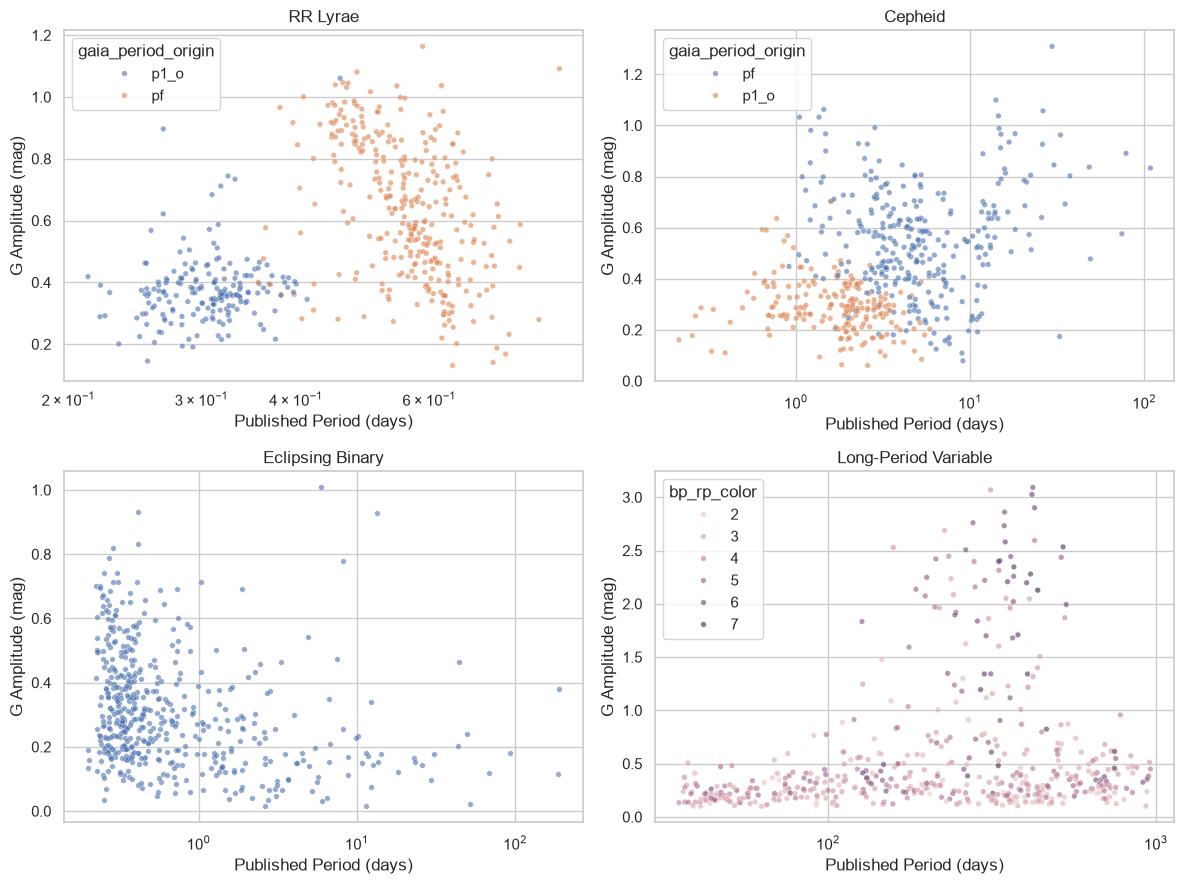

In [22]:
figure, axes = plt.subplots(2, 2, figsize=(12, 9))

for axis, name in zip(axes.flat, CLASSES):
    group = stars.loc[stars["class_name"].eq(name) & stars["gaia_period"].gt(0)]

    if name in ("RR Lyrae", "Cepheid"):
        sns.scatterplot(data=group, x="gaia_period", y="amplitude", hue="gaia_period_origin", s=16, alpha=0.6, ax=axis)
    elif name == "Long-Period Variable":
        sns.scatterplot(data=group, x="gaia_period", y="amplitude", hue="bp_rp_color", s=16, alpha=0.6, ax=axis)
    else:
        sns.scatterplot(data=group, x="gaia_period", y="amplitude", s=16, alpha=0.6, ax=axis)
    axis.set(xscale="log", xlabel="Published Period (days)", ylabel="G Amplitude (mag)", title=name)

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "05_period_amplitude.png", dpi=160, bbox_inches="tight")
plt.show()

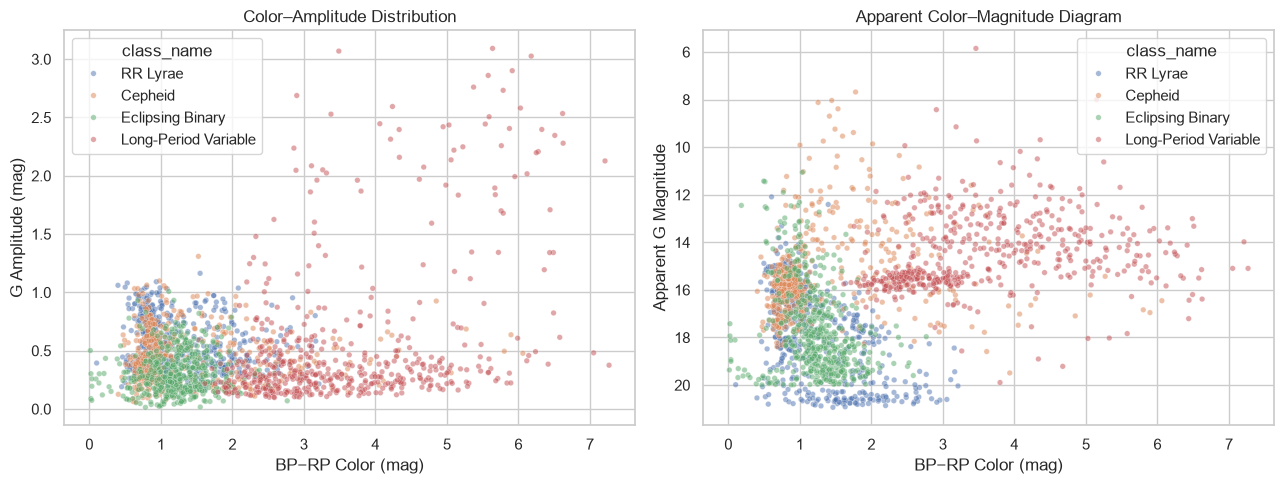

In [23]:
figure, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=stars, x="bp_rp_color", y="amplitude", hue="class_name", hue_order=CLASSES, alpha=0.5, s=16, ax=axes[0])
sns.scatterplot(data=stars, x="bp_rp_color", y="g_mean_magnitude", hue="class_name", hue_order=CLASSES, alpha=0.5, s=16, ax=axes[1])
axes[0].set(title="Color–Amplitude Distribution", xlabel="BP−RP Color (mag)", ylabel="G Amplitude (mag)")
axes[1].invert_yaxis()
axes[1].set(title="Apparent Color–Magnitude Diagram", xlabel="BP−RP Color (mag)", ylabel="Apparent G Magnitude")

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "06_photometric_structure.png", dpi=160, bbox_inches="tight")
plt.show()

In [24]:
overlap = []

for name in CLASSES:
    group = stars.loc[stars["class_name"].eq(name), ["bp_rp_color", "amplitude"]].dropna()

    for comparison in CLASSES:
        if name == comparison:
            continue
        reference = stars.loc[stars["class_name"].eq(comparison), ["bp_rp_color", "amplitude"]].dropna()
        if group.empty or reference.empty:
            continue

        inside = group.ge(reference.quantile(0.05)).all(axis=1) & group.le(reference.quantile(0.95)).all(axis=1)
        overlap.append({"class_name": name, "comparison": comparison, "stars": len(group), "overlap_pct": 100 * inside.mean()})

display(pd.DataFrame(overlap).round(2))

,class_name,comparison,stars,overlap_pct
0,RR Lyrae,Cepheid,463,77.75
1,RR Lyrae,Eclipsing Binary,463,52.92
2,RR Lyrae,Long-Period Variable,463,10.80
3,Cepheid,RR Lyrae,500,63.60
4,Cepheid,Eclipsing Binary,500,61.40
5,Cepheid,Long-Period Variable,500,16.80
6,Eclipsing Binary,RR Lyrae,496,50.81
7,Eclipsing Binary,Cepheid,496,73.39
8,Eclipsing Binary,Long-Period Variable,496,1.61
9,Long-Period Variable,RR Lyrae,500,7.40


## Period Search and Recovery

In [25]:
stars["search_limit"] = np.minimum(MAX_PERIOD, stars["time_span"] / 2)
stars["enough_epochs"] = stars["n_epochs"].ge(MIN_POINTS)
stars["period_low"] = stars["gaia_period"].ge(MIN_PERIOD)
stars["period_high"] = stars["gaia_period"].le(stars["search_limit"])
stars["eligible"] = stars[["enough_epochs", "period_low", "period_high"]].all(axis=1)
stars["observed_cycles"] = stars["time_span"] / stars["gaia_period"]

coverage = stars.assign(
    short_curve=~stars["enough_epochs"],
    short_period=~stars["period_low"],
    long_period=~stars["period_high"]
).groupby("class_name").agg(
    stars=("source_id", "size"),
    eligible=("eligible", "sum"),
    short_curve=("short_curve", "sum"),
    short_period=("short_period", "sum"),
    long_period=("long_period", "sum")
).reindex(CLASSES)

coverage["eligible_pct"] = 100 * coverage["eligible"] / coverage["stars"]

display(coverage.round(2))

,stars,eligible,short_curve,short_period,long_period,eligible_pct
class_name,,,,,,
RR Lyrae,500,478,22,0,0,95.6
Cepheid,500,500,0,0,0,100.0
Eclipsing Binary,500,500,0,0,0,100.0
Long-Period Variable,500,401,0,0,99,80.2


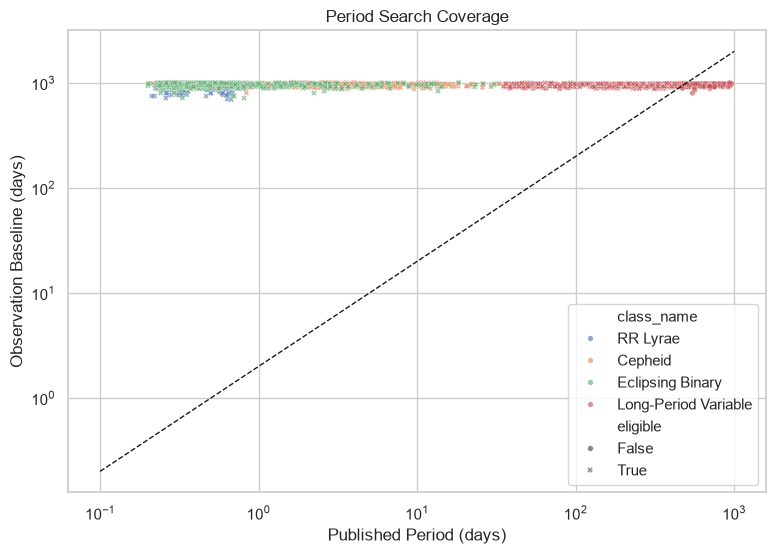

In [26]:
figure, axis = plt.subplots(figsize=(9, 6))

sns.scatterplot(data=stars, x="gaia_period", y="time_span", hue="class_name", style="eligible", s=16, alpha=0.6, ax=axis)
reference = np.geomspace(MIN_PERIOD, max(MAX_PERIOD, stars["gaia_period"].max()), 150)
axis.plot(reference, 2 * reference, "k--", lw=1, label="Two Cycles")
axis.set(xscale="log", yscale="log", xlabel="Published Period (days)", ylabel="Observation Baseline (days)", title="Period Search Coverage")

figure.savefig(FIGURES_ROOT / "07_period_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

### Lomb–Scargle Recovery

In [27]:
def recover(group, minimum=MIN_PERIOD, maximum=MAX_PERIOD, grid=5, weighted=False):
    time = group["g_transit_time"].to_numpy(dtype=float)
    mag = group["g_transit_mag"].to_numpy(dtype=float)
    error = group["magnitude_error"].to_numpy(dtype=float)
    valid = np.isfinite(time) & np.isfinite(mag)

    if weighted:
        valid &= np.isfinite(error) & (error > 0)
    time, mag, error = time[valid], mag[valid], error[valid]

    if len(time) < MIN_POINTS or np.unique(time).size != len(time) or not np.std(mag) > 0:
        return np.nan, np.nan
    time = time - time.min()
    maximum = min(maximum, np.ptp(time) / 2)
    if maximum <= minimum:
        return np.nan, np.nan
    try:
        model = LombScargle(time, mag, dy=error if weighted else None)
        frequency, power = model.autopower(
            minimum_frequency=1 / maximum, maximum_frequency=1 / minimum,
            samples_per_peak=grid
        )
        if not np.isfinite(power).any():
            return np.nan, np.nan
        peak = np.nanargmax(power)
        return float(1 / frequency[peak]), float(power[peak])
    except (ValueError, FloatingPointError, ZeroDivisionError, np.linalg.LinAlgError):
        return np.nan, np.nan

In [28]:
eligible_ids = set(stars.loc[stars["eligible"], "source_id"])
selected = observations.loc[observations["source_id"].isin(eligible_ids)]

light_curves = dict(tuple(selected.groupby("source_id")))
period_results = {}

del selected

In [29]:
name = CLASSES[0]
ids = stars.loc[stars["class_name"].eq(name) & stars["eligible"], "source_id"]

period_results.update({sid: recover(light_curves[sid]) for sid in ids})

print(name, "Processed:", len(ids))

RR Lyrae Processed: 478


In [30]:
name = CLASSES[1]
ids = stars.loc[stars["class_name"].eq(name) & stars["eligible"], "source_id"]

period_results.update({sid: recover(light_curves[sid]) for sid in ids})

print(name, "Processed:", len(ids))

Cepheid Processed: 500


In [31]:
name = CLASSES[2]
ids = stars.loc[stars["class_name"].eq(name) & stars["eligible"], "source_id"]

period_results.update({sid: recover(light_curves[sid]) for sid in ids})

print(name, "Processed:", len(ids))

Eclipsing Binary Processed: 500


In [32]:
name = CLASSES[3]
ids = stars.loc[stars["class_name"].eq(name) & stars["eligible"], "source_id"]

period_results.update({sid: recover(light_curves[sid]) for sid in ids})

print(name, "Processed:", len(ids))

Long-Period Variable Processed: 401


In [33]:
stars["period_estimate"] = stars["source_id"].map({sid: result[0] for sid, result in period_results.items()})
stars["power"] = stars["source_id"].map({sid: result[1] for sid, result in period_results.items()})

print("Estimated Periods:", stars["period_estimate"].notna().sum())

Estimated Periods: 1879


### Period Accuracy and Aliases

In [34]:
stars["period_ratio"] = stars["period_estimate"] / stars["gaia_period"]
stars["relative_error"] = (stars["period_ratio"] - 1).abs()
stars["frequency_offset"] = 1 / stars["period_estimate"] - 1 / stars["gaia_period"]
stars["phase_drift"] = stars["time_span"] * stars["frequency_offset"].abs()

stars["primary_match"] = (
    stars["eligible"]
    & stars["relative_error"].le(TOLERANCE)
    & stars["phase_drift"].le(MAX_DRIFT)
)
stars["other_mode"] = False

for col in ["gaia_pf", "gaia_p1_o", "gaia_p2_o"]:
    if col not in stars:
        continue
    reference = pd.to_numeric(stars[col], errors="coerce")
    stars["other_mode"] |= (stars["eligible"] & stars["class_name"].isin(["RR Lyrae", "Cepheid"]) & reference.gt(0)
        & (stars["period_estimate"] / reference - 1).abs().le(TOLERANCE)
        & (stars["time_span"] * (1 / stars["period_estimate"] - 1 / reference).abs()).le(MAX_DRIFT))

stars["other_mode"] &= ~stars["primary_match"]
stars["recovered"] = stars["primary_match"] | stars["other_mode"]

In [35]:
stars["half_alias"] = False
stars["double_alias"] = False

for col in ["gaia_period", "gaia_pf", "gaia_p1_o", "gaia_p2_o"]:
    if col not in stars:
        continue
    reference = pd.to_numeric(stars[col], errors="coerce")
    permitted = stars["class_name"].isin(["RR Lyrae", "Cepheid"]) if col != "gaia_period" else True
    stars["half_alias"] |= (reference.gt(0) & permitted & (stars["period_estimate"] / reference - 0.5).abs().le(0.5 * TOLERANCE))
    stars["double_alias"] |= (reference.gt(0) & permitted & (stars["period_estimate"] / reference - 2).abs().le(2 * TOLERANCE))

stars["period_status"] = np.select(
    [~stars["eligible"], stars["period_estimate"].isna(), stars["primary_match"], stars["other_mode"], stars["half_alias"], stars["double_alias"]],
    ["Ineligible", "No Estimate", "Recovered", "Other Mode", "Half Alias", "Double Alias"], default="Mismatch",
)

eligible = stars.loc[stars["eligible"]].copy()
status_counts = pd.crosstab(stars["class_name"], stars["period_status"]).reindex(CLASSES, fill_value=0)

display(status_counts)

period_status,Double Alias,Half Alias,Ineligible,Mismatch,Other Mode,Recovered
class_name,,,,,,
RR Lyrae,2,9,22,75,0,392
Cepheid,0,0,0,4,1,495
Eclipsing Binary,6,379,0,103,0,12
Long-Period Variable,0,0,99,132,0,269


### Recovery Rates and Tolerance Checks

In [36]:
recovery = eligible.groupby("class_name")["recovered"].agg(["size", "sum", "mean"]).reindex(CLASSES)
recovery.columns = ["eligible", "recovered", "rate"]

count = recovery["eligible"].replace(0, np.nan)
rate = recovery["rate"]
center = (rate + 1.96**2 / (2 * count)) / (1 + 1.96**2 / count)
margin = 1.96 / (1 + 1.96**2 / count) * np.sqrt(rate * (1 - rate) / count + 1.96**2 / (4 * count**2))

recovery["lower"], recovery["upper"] = center - margin, center + margin

display(recovery.round(3))

,eligible,recovered,rate,lower,upper
class_name,,,,,
RR Lyrae,478,392,0.820,0.783,0.852
Cepheid,500,496,0.992,0.980,0.997
Eclipsing Binary,500,12,0.024,0.014,0.041
Long-Period Variable,401,269,0.671,0.623,0.715


In [37]:
sensitivity = []

for tolerance in [0.05, 0.10, 0.20]:
    for name in CLASSES:
        group = eligible.loc[eligible["class_name"].eq(name)]
        hits = group["relative_error"].le(tolerance) & group["phase_drift"].le(MAX_DRIFT)

        if name in ("RR Lyrae", "Cepheid"):
            for col in ["gaia_pf", "gaia_p1_o", "gaia_p2_o"]:
                if col in group:
                    reference = pd.to_numeric(group[col], errors="coerce")
                    hits |= (
                        reference.gt(0)
                        & (group["period_estimate"] / reference - 1).abs().le(tolerance)
                        & (group["time_span"] * (1 / group["period_estimate"] - 1 / reference).abs()).le(MAX_DRIFT)
                    )

        sensitivity.append({
            "class_name": name, "tolerance_pct": 100 * tolerance,
            "eligible": len(group),
            "recovery_pct": 100 * hits.sum() / len(group) if len(group) else np.nan
        })

display(pd.DataFrame(sensitivity).round(2))

,class_name,tolerance_pct,eligible,recovery_pct
0,RR Lyrae,5.0,478,82.01
1,Cepheid,5.0,500,99.20
2,Eclipsing Binary,5.0,500,2.40
3,Long-Period Variable,5.0,401,65.34
4,RR Lyrae,10.0,478,82.01
5,Cepheid,10.0,500,99.20
6,Eclipsing Binary,10.0,500,2.40
7,Long-Period Variable,10.0,401,67.08
8,RR Lyrae,20.0,478,82.01
9,Cepheid,20.0,500,99.20


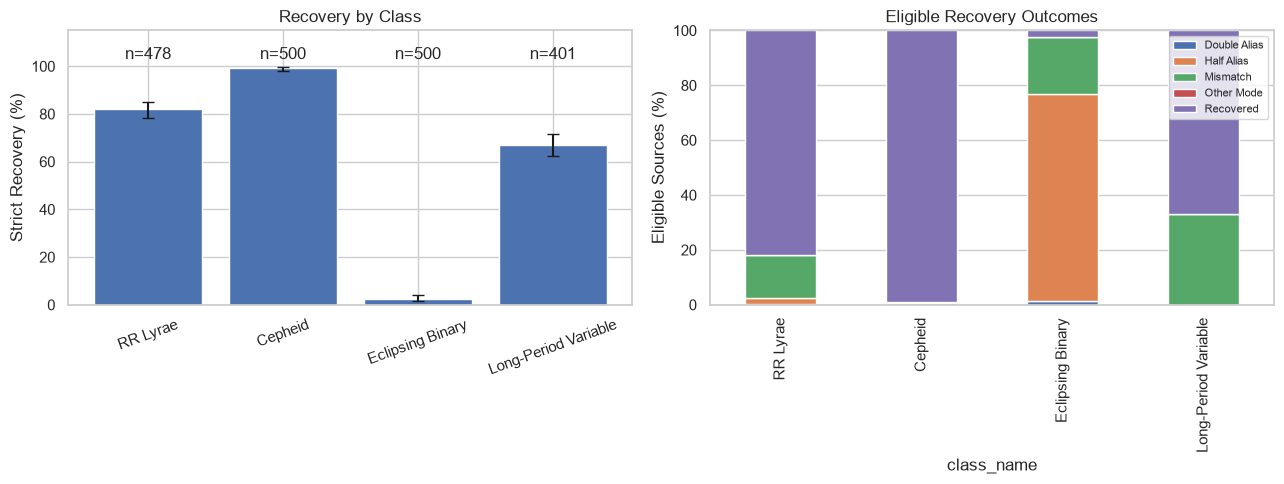

In [38]:
outcomes = pd.crosstab(eligible["class_name"], eligible["period_status"]).reindex(CLASSES, fill_value=0)

figure, axes = plt.subplots(1, 2, figsize=(13, 5))
position = np.arange(len(CLASSES))

axes[0].bar(
    position, recovery["rate"].to_numpy() * 100,
    yerr=100 * np.vstack([
        recovery["rate"] - recovery["lower"],
        recovery["upper"] - recovery["rate"]]),
    capsize=4)

axes[0].set_xticks(position, CLASSES, rotation=20)
axes[0].set(ylim=(0, 115), ylabel="Strict Recovery (%)", title="Recovery by Class")

for index, total in enumerate(recovery["eligible"]):
    axes[0].text(index, 103, f"n={total}", ha="center")
(100 * outcomes.div(outcomes.sum(axis=1), axis=0)).plot.bar(stacked=True, ax=axes[1])

axes[1].set(ylim=(0, 100), ylabel="Eligible Sources (%)", title="Eligible Recovery Outcomes")
axes[1].legend(fontsize=8)

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "08_period_recovery.png", dpi=160, bbox_inches="tight")

plt.show()

### Weighted Periodograms and Search Sensitivity

In [39]:
def matches(period, star, baseline, tolerance=TOLERANCE):
    if not np.isfinite(period) or period <= 0 or not np.isfinite(baseline) or baseline <= 0:
        return False

    references = [star["gaia_period"]]

    if star["class_name"] in ("RR Lyrae", "Cepheid"):
        references += [star[col] for col in ["gaia_pf", "gaia_p1_o", "gaia_p2_o"] if col in star]

    return any(
        pd.notna(ref) and np.isfinite(ref) and ref > 0
        and abs(period / ref - 1) <= tolerance
        and baseline * abs(1 / period - 1 / ref) <= MAX_DRIFT
        for ref in references
    )

In [40]:
def compare_class(name):
    rows = []

    for _, star in eligible.loc[eligible["class_name"].eq(name)].iterrows():
        group = light_curves[star["source_id"]]
        subset = group.loc[group["magnitude_error"].gt(0) & np.isfinite(group["magnitude_error"])]

        span = subset["g_transit_time"].max() - subset["g_transit_time"].min() if len(subset) else np.nan
        comparable = len(subset) >= MIN_POINTS and MIN_PERIOD <= star["gaia_period"] <= min(MAX_PERIOD, span / 2)

        if comparable:
            unweighted, _ = recover(subset)
            weighted, _ = recover(subset, weighted=True)
        else:
            unweighted = weighted = np.nan

        rows.append({
            "class_name": star["class_name"], "comparable": comparable,
            "unweighted": matches(unweighted, star, span),
            "weighted": matches(weighted, star, span)
        })

    return rows

In [41]:
rr_pair = compare_class(CLASSES[0])
print(CLASSES[0], "Processed:", len(rr_pair))

RR Lyrae Processed: 478


In [42]:
cep_pair = compare_class(CLASSES[1])
print(CLASSES[1], "Processed:", len(cep_pair))

Cepheid Processed: 500


In [43]:
eb_pair = compare_class(CLASSES[2])
print(CLASSES[2], "Processed:", len(eb_pair))

Eclipsing Binary Processed: 500


In [44]:
lpv_pair = compare_class(CLASSES[3])
print(CLASSES[3], "Processed:", len(lpv_pair))

Long-Period Variable Processed: 401


In [45]:
paired = pd.DataFrame(rr_pair + cep_pair + eb_pair + lpv_pair)

display(paired.groupby("class_name")["comparable"].agg(["size", "sum"]).reindex(CLASSES))

if paired["comparable"].any():
    rates = paired.loc[paired["comparable"]].groupby("class_name")[["unweighted", "weighted"]].mean()
    display((100 * rates).reindex(CLASSES).round(2))

,size,sum
class_name,,
RR Lyrae,478,478
Cepheid,500,500
Eclipsing Binary,500,500
Long-Period Variable,401,401


,unweighted,weighted
class_name,,
RR Lyrae,82.01,68.20
Cepheid,99.20,99.00
Eclipsing Binary,2.40,1.60
Long-Period Variable,67.08,54.61


In [46]:
configs = {
    "Baseline": (0.1, 1000, 5),
    "Fine Grid": (0.1, 1000, 10),
    "Short Range": (0.2, 500, 5),
    "Wide Range": (0.05, 1500, 5)
}

common = eligible.loc[eligible["gaia_period"].between(0.2, 500)]

if len(common):
    common = pd.concat([
        group.sample(min(15, len(group)), random_state=SEED)
        for _, group in common.groupby("class_name")
    ], ignore_index=True)

config_rows = []

for _, star in common.iterrows():
    group = light_curves[star["source_id"]]

    for name, (minimum, maximum, grid) in configs.items():
        period, _ = recover(group, minimum, maximum, grid)

        config_rows.append({
            "class_name": star["class_name"],
            "configuration": name,
            "recovered": matches(period, star, star["time_span"])
        })

if config_rows:
    results = pd.DataFrame(config_rows)
    display(results.groupby(["class_name", "configuration"])["recovered"].agg(["size", "mean"]).round(3))

size   mean
class_name           configuration             
Cepheid              Baseline         15  1.000
                     Fine Grid        15  1.000
                     Short Range      15  1.000
                     Wide Range       15  1.000
Eclipsing Binary     Baseline         15  0.000
                     Fine Grid        15  0.000
                     Short Range      15  0.000
                     Wide Range       15  0.000
Long-Period Variable Baseline         15  0.733
                     Fine Grid        15  0.733
                     Short Range      15  0.733
                     Wide Range       15  0.600
RR Lyrae             Baseline         15  0.867
                     Fine Grid        15  0.867
                     Short Range      15  1.000
                     Wide Range       15  0.867

### Period Comparison and Aliasing

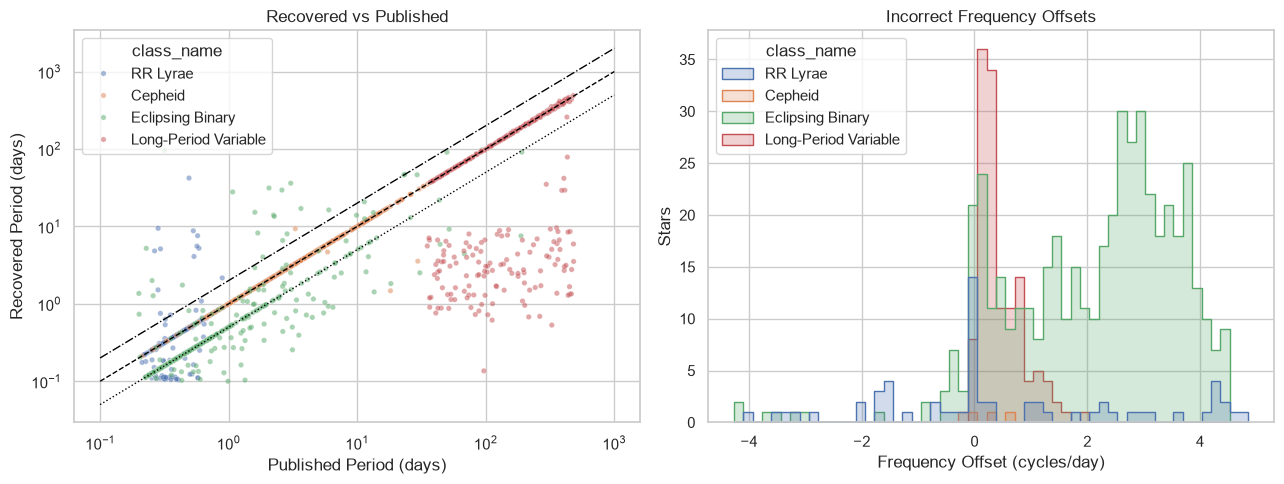

In [47]:
matched = eligible.loc[eligible["period_estimate"].gt(0)]
wrong = eligible.loc[~eligible["recovered"] & np.isfinite(eligible["frequency_offset"])]

figure, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=matched, x="gaia_period", y="period_estimate",
    hue="class_name", hue_order=CLASSES, s=15, alpha=0.5, ax=axes[0]
)

reference = np.geomspace(MIN_PERIOD, MAX_PERIOD, 150)

for factor, style in [(1, "--"), (0.5, ":"), (2, "-.")]:
    axes[0].plot(reference, reference * factor, color="black", ls=style, lw=1)

axes[0].set(
    xscale="log", yscale="log", xlabel="Published Period (days)",
    ylabel="Recovered Period (days)", title="Recovered vs Published"
)

sns.histplot(
    data=wrong.loc[wrong["frequency_offset"].abs().lt(5)],
    x="frequency_offset", hue="class_name", hue_order=CLASSES,
    element="step", bins=55, ax=axes[1]
)

axes[1].set(
    xlabel="Frequency Offset (cycles/day)",
    ylabel="Stars", title="Incorrect Frequency Offsets"
)

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "09_aliases.png", dpi=160, bbox_inches="tight")
plt.show()

In [48]:
display(
    eligible.groupby(["class_name", "period_status"])[
        ["n_epochs", "time_span", "amplitude_ratio", "frequency_offset"]
    ].median().round(3)
)

n_epochs  time_span  amplitude_ratio  \
class_name           period_status                                         
Cepheid              Mismatch           31.5    960.112          632.247   
                     Other Mode         58.0   1001.153           21.515   
                     Recovered          39.0    979.981          161.801   
Eclipsing Binary     Double Alias       36.5    964.224           13.387   
                     Half Alias         41.0    959.343           35.334   
                     Mismatch           37.0    959.519           16.736   
                     Recovered          39.0    959.519           14.917   
Long-Period Variable Mismatch           40.0    962.290          110.808   
                     Recovered          44.0    931.443          169.741   
RR Lyrae             Double Alias       22.5    930.959           10.134   
                     Half Alias         34.0    924.964            7.887   
                     Mismatch           28.0    919.756            8.743   
                     Recovered          38.0    954.872           90.747   

                                    frequency_offset  
class_name           period_status                    
Cepheid              Mismatch                  0.123  
                     Other Mode                0.044  
                     Recovered                 0.000  
Eclipsing Binary     Double Alias             -0.031  
                     Half Alias                2.716  
                     Mismatch                  0.377  
                     Recovered                 0.000  
Long-Period Variable Mismatch                  0.317  
                     Recovered                -0.000  
RR Lyrae             Double Alias             -1.488  
                     Half Alias                4.108  
                     Mismatch                  1.000  
                     Recovered                 0.000

### Phase-Folded Examples

In [49]:
examples = []

for name in CLASSES:
    group = eligible.loc[eligible["class_name"].eq(name) & eligible["period_estimate"].notna()]
    wrong = group.loc[~group["recovered"]]

    if name == "Eclipsing Binary" and wrong["period_status"].eq("Half Alias").any():
        wrong = wrong.loc[wrong["period_status"].eq("Half Alias")]

    if len(wrong):
        examples.append(("Incorrect", wrong.iloc[(wrong["n_epochs"] - wrong["n_epochs"].median()).abs().argmin()]))

if eligible["recovered"].any():
    good = eligible.loc[eligible["recovered"] & eligible["period_estimate"].notna()]
    examples.insert(0, ("Recovered", good.iloc[(good["n_epochs"] - good["n_epochs"].median()).abs().argmin()]))

examples = examples[:5]

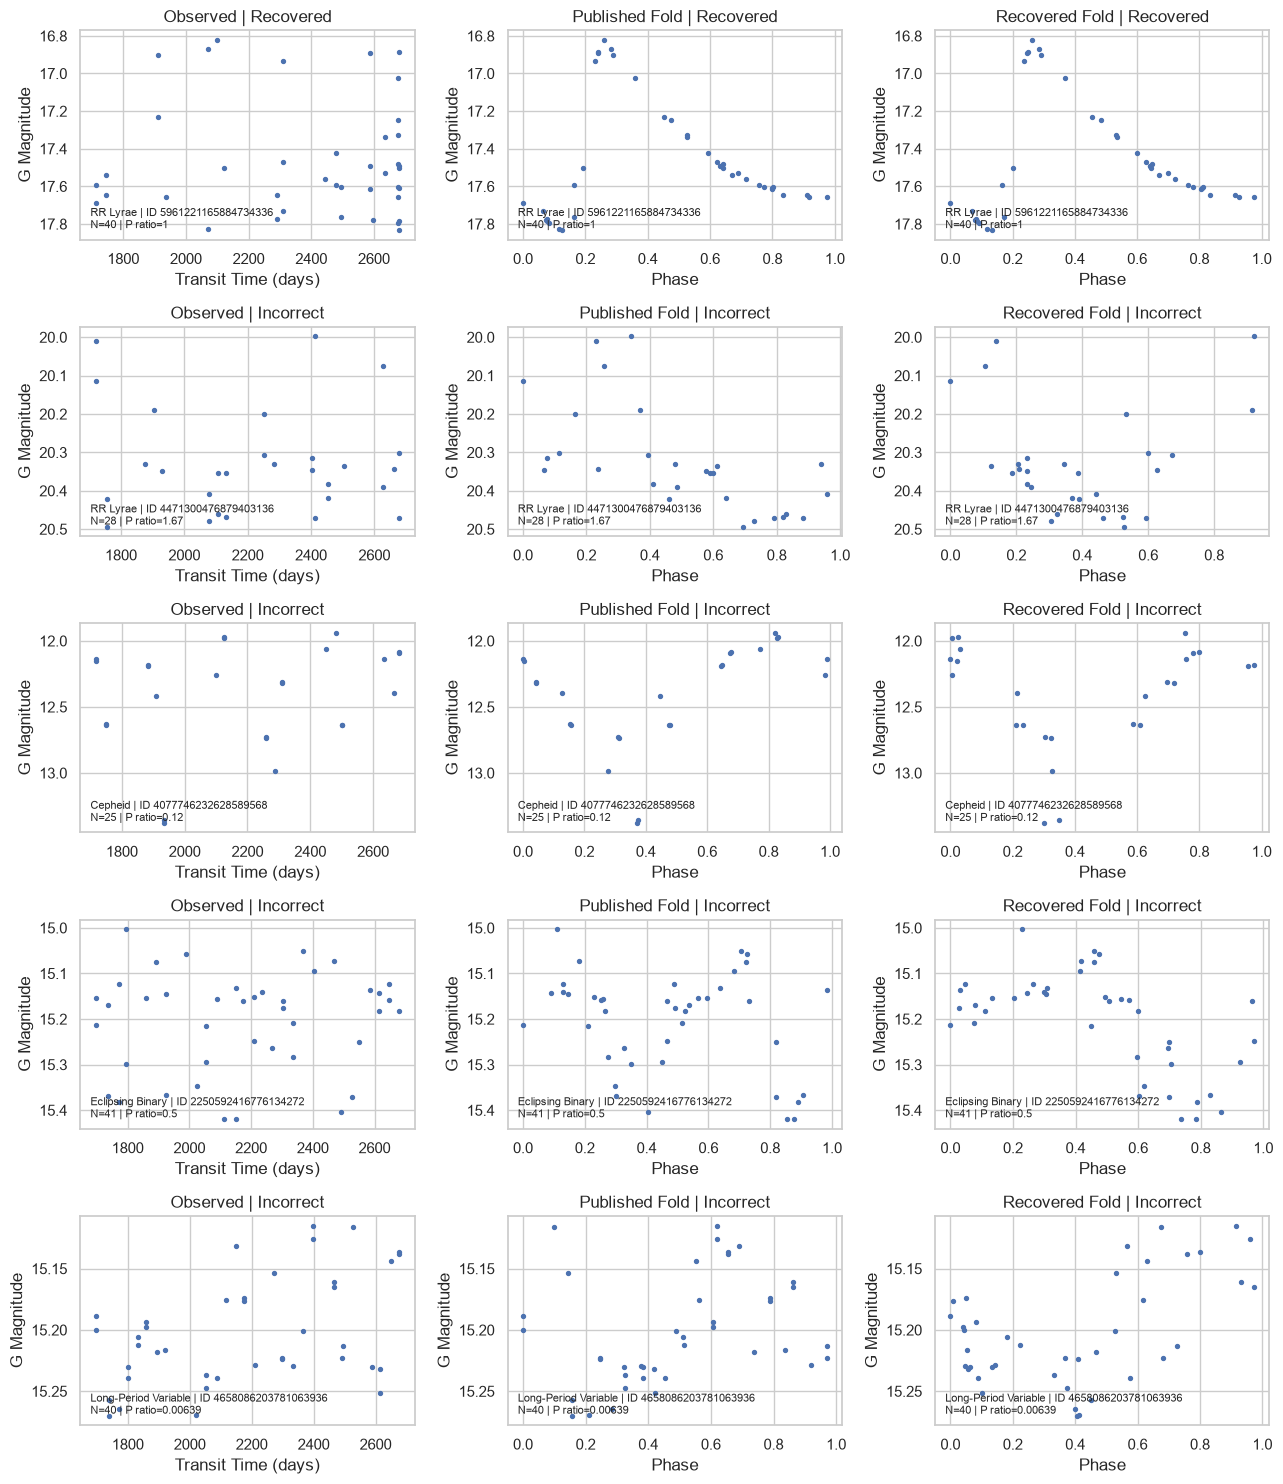

In [50]:
if examples:
    figure, axes = plt.subplots(len(examples), 3, figsize=(13, 3 * len(examples)), squeeze=False)

    for row, (status, star) in enumerate(examples):
        light = light_curves[star["source_id"]]
        time = light["g_transit_time"].to_numpy(dtype=float)
        mag = light["g_transit_mag"].to_numpy(dtype=float)

        periods = [None, star["gaia_period"], star["period_estimate"]]
        titles = ["Observed", "Published Fold", "Recovered Fold"]

        for axis, period, title in zip(axes[row], periods, titles):
            phase = ((time - time.min()) / period) % 1 if period is not None else time

            axis.scatter(phase, mag, s=8)
            axis.invert_yaxis()
            axis.set(
                title=f"{title} | {status}",
                xlabel="Phase" if period is not None else "Transit Time (days)",
                ylabel="G Magnitude"
            )
            axis.text(
                0.03, 0.04,
                f"{star['class_name']} | ID {int(star['source_id'])}\nN={star['n_epochs']} | P ratio={star['period_ratio']:.3g}",
                transform=axis.transAxes, fontsize=8, va="bottom"
            )

    figure.tight_layout()
    figure.savefig(FIGURES_ROOT / "10_phase_folds.png", dpi=160, bbox_inches="tight")
    plt.show()

### Spectral Window

In [51]:
window_examples = eligible.loc[eligible["period_estimate"].notna()].copy()

wrong_example = window_examples.loc[~window_examples["recovered"]].sort_values("abs_latitude")
good_example = window_examples.loc[window_examples["recovered"]].sort_values("abs_latitude")

selected = []
if len(wrong_example):
    selected.append(wrong_example.iloc[len(wrong_example) // 2])

if len(good_example):
    selected.append(good_example.iloc[len(good_example) // 2])

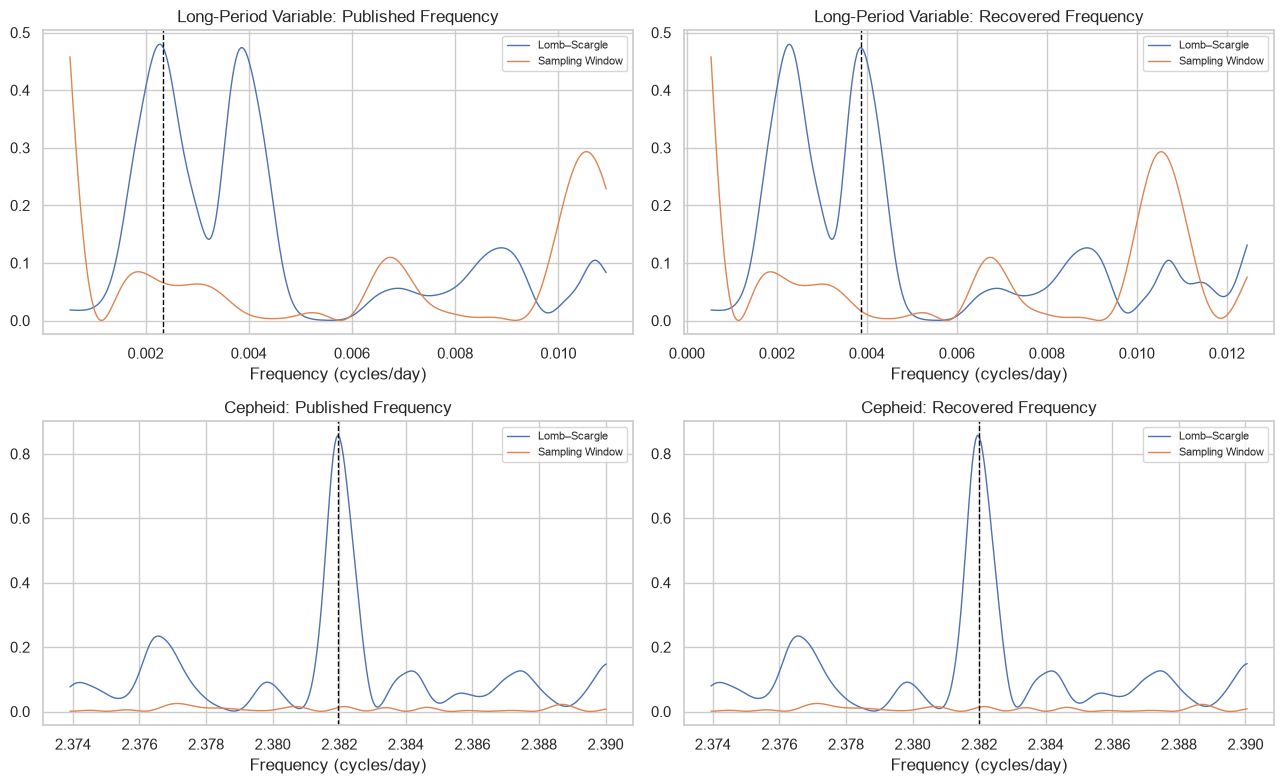

In [52]:
if selected:
    figure, axes = plt.subplots(len(selected), 2, figsize=(13, 4 * len(selected)), squeeze=False)

    for row, star in enumerate(selected):
        light = light_curves[star["source_id"]]
        time = light["g_transit_time"].to_numpy(dtype=float, copy=True)
        time -= time.min()

        span = np.ptp(time)
        spectrum = LombScargle(time, light["g_transit_mag"].to_numpy(dtype=float))

        centers = [1 / star["gaia_period"], 1 / star["period_estimate"]]
        titles = ["Published Frequency", "Recovered Frequency"]

        for axis, center, title in zip(axes[row], centers, titles):
            frequency = np.linspace(max(1 / (2 * span), center - 8 / span), center + 8 / span, 321)
            window = np.abs(np.exp(-2j * np.pi * np.outer(frequency, time)).mean(axis=1)) ** 2

            axis.plot(frequency, spectrum.power(frequency), lw=1, label="Lomb–Scargle")
            axis.plot(frequency, window, lw=1, label="Sampling Window")
            axis.axvline(center, color="black", ls="--", lw=1)
            axis.set(xlabel="Frequency (cycles/day)", title=f"{star['class_name']}: {title}")
            axis.legend(fontsize=8)

    figure.tight_layout()
    figure.savefig(FIGURES_ROOT / "11_sampling_window.png", dpi=160, bbox_inches="tight")
    plt.show()

## Controlled Observational Sampling

In [53]:
levels = [20, 30, 40]
repetitions = 20

candidates = eligible.loc[eligible["n_epochs"].ge(max(levels))]

if len(candidates):
    control = pd.concat([
        group.sample(min(50, len(group)), random_state=SEED)
        for _, group in candidates.groupby("class_name")
    ], ignore_index=True)
else:
    control = candidates

print("Sampled Stars:", len(control))

Sampled Stars: 200


In [54]:
def sample_class(name):
    rows = []

    for _, star in control.loc[control["class_name"].eq(name)].iterrows():
        group = light_curves[star["source_id"]]

        for count in levels:
            for repeat in range(repetitions):
                random = np.random.default_rng(
                    np.random.SeedSequence([SEED, int(star["source_id"]) % 2**32, count, repeat])
                )

                interior = random.choice(np.arange(1, len(group) - 1), count - 2, replace=False)
                subset = group.iloc[np.r_[0, np.sort(interior), len(group) - 1]]
                span = subset["g_transit_time"].max() - subset["g_transit_time"].min()
                period, _ = recover(subset)

                rows.append({
                    "source_id": star["source_id"],
                    "class_name": star["class_name"],
                    "epochs": count,
                    "baseline": span,
                    "recovered": matches(period, star, span)
                })

    return rows

In [55]:
rr_trials = sample_class(CLASSES[0])
print(CLASSES[0], "Trials:", len(rr_trials))

RR Lyrae Trials: 3000


In [56]:
cep_trials = sample_class(CLASSES[1])
print(CLASSES[1], "Trials:", len(cep_trials))

Cepheid Trials: 3000


In [57]:
eb_trials = sample_class(CLASSES[2])
print(CLASSES[2], "Trials:", len(eb_trials))

Eclipsing Binary Trials: 3000


In [58]:
lpv_trials = sample_class(CLASSES[3])
print(CLASSES[3], "Trials:", len(lpv_trials))

Long-Period Variable Trials: 3000


In [59]:
trials = pd.DataFrame(rr_trials + cep_trials + eb_trials + lpv_trials)

if len(trials):
    star_rates = trials.groupby(["class_name", "source_id", "epochs"]).agg(
        recovery=("recovered", "mean"),
        baseline=("baseline", "median")
    ).reset_index()

    summary = star_rates.groupby(["class_name", "epochs"]).agg(
        stars=("source_id", "size"),
        recovery=("recovery", "mean"),
        variability=("recovery", "std"),
        baseline=("baseline", "median")
    )

    display(summary.round(3))

stars  recovery  variability  baseline
class_name           epochs                                        
Cepheid              20         50     0.904        0.223   981.069
                     30         50     0.963        0.141   981.069
                     40         50     1.000        0.000   981.069
Eclipsing Binary     20         50     0.014        0.086   989.955
                     30         50     0.023        0.115   989.955
                     40         50     0.036        0.158   989.955
Long-Period Variable 20         50     0.331        0.359   928.071
                     30         50     0.497        0.395   928.071
                     40         50     0.564        0.401   928.071
RR Lyrae             20         50     0.536        0.356   953.426
                     30         50     0.828        0.349   953.426
                     40         50     0.882        0.301   953.426

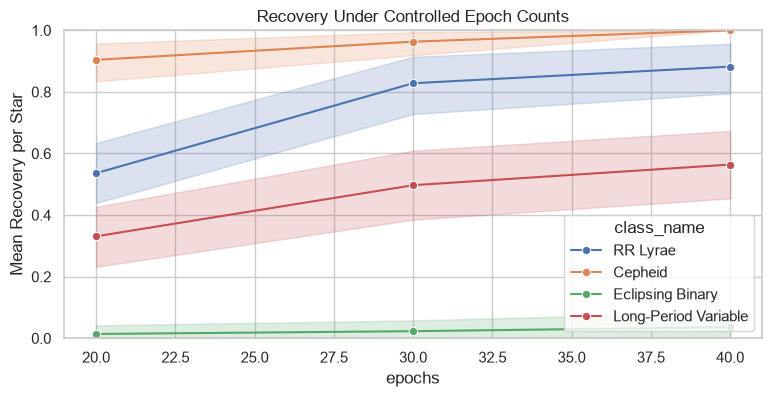

In [60]:
if len(trials):
    figure, axis = plt.subplots(figsize=(9, 4))

    sns.lineplot(
        data=star_rates, x="epochs", y="recovery",
        hue="class_name", hue_order=CLASSES, marker="o",
        errorbar=("ci", 95), ax=axis
    )

    axis.set(
        ylim=(0, 1), ylabel="Mean Recovery per Star",
        title="Recovery Under Controlled Epoch Counts"
    )

    figure.savefig(FIGURES_ROOT / "12_epoch_subsampling.png", dpi=160, bbox_inches="tight")
    plt.show()

## Class-Specific Recovery Diagnostics

In [61]:
eligible["recovery_group"] = np.where(eligible["recovered"], "Recovered", "Incorrect")

recovery_properties = eligible.groupby(["class_name", "recovery_group"]).agg(
    stars=("source_id", "size"),
    epochs=("n_epochs", "median"),
    baseline=("time_span", "median"),
    median_gap=("median_gap", "median"),
    uncertainty=("median_error", "median"),
    signal=("amplitude_ratio", "median"),
    amplitude=("amplitude", "median")
).round(3)

display(recovery_properties)

stars  epochs  baseline  median_gap  \
class_name           recovery_group                                        
Cepheid              Incorrect           4    31.5   960.112      22.838   
                     Recovered         496    39.0   979.981      27.014   
Eclipsing Binary     Incorrect         488    40.0   959.343       6.967   
                     Recovered          12    39.0   959.519      22.338   
Long-Period Variable Incorrect         132    40.0   962.290      25.883   
                     Recovered         269    44.0   931.443       3.590   
RR Lyrae             Incorrect          86    28.0   920.077      10.806   
                     Recovered         392    38.0   954.872       0.250   

                                     uncertainty   signal  amplitude  
class_name           recovery_group                                   
Cepheid              Incorrect             0.002  632.247      0.744  
                     Recovered             0.002  161.714      0.403  
Eclipsing Binary     Incorrect             0.009   30.085      0.279  
                     Recovered             0.012   14.917      0.178  
Long-Period Variable Incorrect             0.002  110.808      0.243  
                     Recovered             0.003  169.741      0.410  
RR Lyrae             Incorrect             0.045    8.608      0.395  
                     Recovered             0.006   90.747      0.528

In [62]:
eligible["epoch_bin"] = pd.qcut(eligible["n_epochs"], 3, duplicates="drop")
eligible["latitude_bin"] = pd.cut(eligible["abs_latitude"], [0, 30, 60, 90], include_lowest=True)

joint = eligible.groupby(["class_name", "epoch_bin", "latitude_bin"], observed=True).agg(
    stars=("source_id", "size"),
    recovered=("recovered", "sum")
).reset_index()

joint["rate"] = 100 * joint["recovered"] / joint["stars"]

display(joint.round(2))

,class_name,epoch_bin,latitude_bin,stars,recovered,rate
0,Cepheid,"(19.999, 36.0]","(-0.001, 30.0]",36,34,94.44
1,Cepheid,"(19.999, 36.0]","(30.0, 60.0]",5,5,100.00
2,Cepheid,"(19.999, 36.0]","(60.0, 90.0]",124,124,100.00
3,Cepheid,"(36.0, 44.0]","(-0.001, 30.0]",10,10,100.00
4,Cepheid,"(36.0, 44.0]","(30.0, 60.0]",16,16,100.00
5,Cepheid,"(36.0, 44.0]","(60.0, 90.0]",164,163,99.39
6,Cepheid,"(44.0, 130.0]","(-0.001, 30.0]",19,19,100.00
7,Cepheid,"(44.0, 130.0]","(30.0, 60.0]",84,83,98.81
8,Cepheid,"(44.0, 130.0]","(60.0, 90.0]",42,42,100.00
9,Eclipsing Binary,"(19.999, 36.0]","(-0.001, 30.0]",145,4,2.76


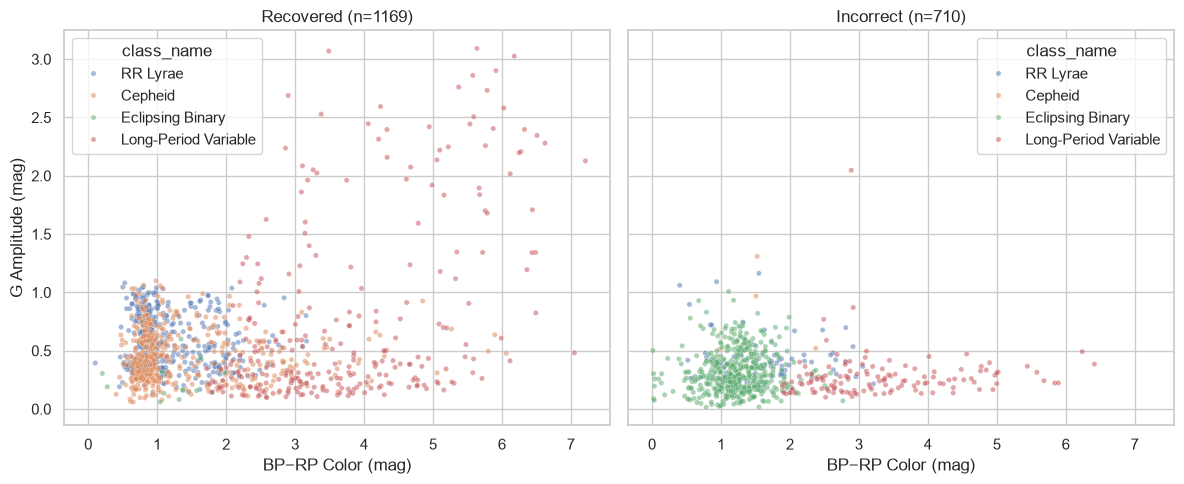

In [63]:
figure, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for axis, status in zip(axes, ["Recovered", "Incorrect"]):
    group = eligible.loc[eligible["recovery_group"].eq(status)]
    sns.scatterplot(data=group, x="bp_rp_color", y="amplitude", hue="class_name", hue_order=CLASSES, alpha=0.5, s=14, ax=axis)
    axis.set(title=f"{status} (n={len(group)})", xlabel="BP−RP Color (mag)", ylabel="G Amplitude (mag)")

figure.tight_layout()
figure.savefig(FIGURES_ROOT / "13_recovery_photometry.png", dpi=160, bbox_inches="tight")
plt.show()

### Adjusted Latitude Association and Uncertainty

In [64]:
associations = []

for name in CLASSES:

    group = eligible.loc[eligible["class_name"].eq(name)].copy()
    group["log_period"] = np.log10(group["gaia_period"])
    group["log_error"] = np.log10(group["median_error"].where(group["median_error"].gt(0)))
    group["log_signal"] = np.log10(group["amplitude_ratio"].where(group["amplitude_ratio"].gt(0)))
    controls = ["n_epochs", "time_span", "log_period", "g_mean_magnitude", "log_error", "log_signal"]
    group = group[["abs_latitude", "recovered", *controls]].replace([np.inf, -np.inf], np.nan).dropna()
    status = "Valid"

    if len(group) < 40 or group["recovered"].nunique() < 2:
        status = "Insufficient Data"
    else:
        ranked = group.rank(pct=True)
        matrix = ranked[controls].to_numpy(dtype=float)
        scales = matrix.std(axis=0)
        if (scales < 1e-8).any():
            status = "Constant Predictor"
        else:
            design = np.column_stack([np.ones(len(group)), (matrix - matrix.mean(axis=0)) / scales])
            if np.linalg.matrix_rank(design) < design.shape[1] or np.linalg.cond(design) > 1e5:
                status = "Collinear Predictors"

    corr = effect = lower = upper = np.nan

    if status == "Valid":
        latitude = ranked["abs_latitude"].to_numpy(dtype=float, copy=True)
        outcome = ranked["recovered"].to_numpy(dtype=float, copy=True)
        latitude -= design @ np.linalg.lstsq(design, latitude, rcond=None)[0]
        outcome -= design @ np.linalg.lstsq(design, outcome, rcond=None)[0]
        corr = np.corrcoef(latitude, outcome)[0, 1]

        if not np.isfinite(corr):
            status = "Unstable Residuals"
        else:
            model = np.column_stack([design, group["abs_latitude"].to_numpy(dtype=float) / 15])
            if np.linalg.matrix_rank(model) < model.shape[1]:
                status = "Collinear Predictors"
            else:
                response = group["recovered"].to_numpy(dtype=float)
                coefficients = np.linalg.lstsq(model, response, rcond=None)[0]
                residuals = response - model @ coefficients
                inverse = np.linalg.pinv(model.T @ model)
                leverage = np.sum((model @ inverse) * model, axis=1)
                adjusted = model * (residuals / (1 - leverage))[:, None]
                covariance = inverse @ (adjusted.T @ adjusted) @ inverse
                error = np.sqrt(max(covariance[-1, -1], 0))
                effect = 100 * coefficients[-1]
                lower, upper = 100 * (coefficients[-1] + np.array([-1.96, 1.96]) * error)

    associations.append({"class_name": name, "stars": len(group), "adjusted_corr": corr,
                         "effect_pp_per_15deg": effect, "lower_95": lower, "upper_95": upper, "status": status})

display(pd.DataFrame(associations).round(3))

,class_name,stars,adjusted_corr,effect_pp_per_15deg,lower_95,upper_95,status
0,RR Lyrae,478,-0.055,-0.688,-3.096,1.720,Valid
1,Cepheid,500,0.081,0.509,-0.372,1.391,Valid
2,Eclipsing Binary,500,0.079,0.871,-0.689,2.431,Valid
3,Long-Period Variable,401,-0.107,-4.037,-7.369,-0.705,Valid


### Outliers and Correlations

In [65]:
outliers = []

for name, group in stars.groupby("class_name"):
    low, high = group["amplitude"].quantile([0.25, 0.75])
    outliers.append(group.loc[group["amplitude"].gt(high + 3 * (high - low))])

outliers = pd.concat(outliers, ignore_index=True)
display(outliers[["source_id", "class_name", "n_epochs", "amplitude", "median_error", "amplitude_ratio"]].head(12))

,source_id,class_name,n_epochs,amplitude,median_error,amplitude_ratio
0,2054144838905388800,Long-Period Variable,52,2.158266,0.029466,73.246179
1,246614208939556480,Long-Period Variable,51,2.580675,0.004456,579.202712
2,5834135415697962752,Long-Period Variable,56,2.396506,0.006800,352.435290
3,5937083896379389696,Long-Period Variable,60,1.837788,0.005147,357.078521
4,5937181233149586944,Long-Period Variable,46,2.405479,0.003620,664.413362
5,5937188895356306432,Long-Period Variable,47,2.219718,0.011048,200.906822
6,5278499658445161600,Long-Period Variable,37,2.050888,0.010278,199.548416
7,6030046951656251648,Long-Period Variable,86,1.961615,0.003245,604.433250
8,4152356106699579648,Long-Period Variable,25,2.074168,0.025414,81.614624
9,4152369708848825856,Long-Period Variable,24,1.992675,0.007484,266.274340


In [66]:
corr_cols = [
    "n_epochs", "time_span", "median_gap", "abs_latitude",
    "bp_rp_color", "amplitude", "median_error", "amplitude_ratio"
]

for name in CLASSES:
    group = stars.loc[stars["class_name"].eq(name), corr_cols].replace([np.inf, -np.inf], np.nan)
    corr = group.corr(method="spearman")
    counts = group.notna().astype(int).T @ group.notna().astype(int)

    results = pd.DataFrame({
        "class_name": name,
        "first": [col for col in corr_cols for _ in corr_cols],
        "second": corr_cols * len(corr_cols),
        "corr": corr.to_numpy().ravel(),
        "n": counts.to_numpy().ravel()
    })

    results = results.query("first != second and n >= 30")
    results = results.assign(abs_corr=lambda data: data["corr"].abs())

    display(results.sort_values("abs_corr", ascending=False).head(8).round(3))

,class_name,first,second,corr,n,abs_corr
62,RR Lyrae,amplitude_ratio,median_error,-0.939,500,0.939
55,RR Lyrae,median_error,amplitude_ratio,-0.939,500,0.939
16,RR Lyrae,median_gap,n_epochs,-0.646,500,0.646
2,RR Lyrae,n_epochs,median_gap,-0.646,500,0.646
38,RR Lyrae,bp_rp_color,median_error,0.518,463,0.518
52,RR Lyrae,median_error,bp_rp_color,0.518,463,0.518
60,RR Lyrae,amplitude_ratio,bp_rp_color,-0.502,463,0.502
39,RR Lyrae,bp_rp_color,amplitude_ratio,-0.502,463,0.502


,class_name,first,second,corr,n,abs_corr
62,Cepheid,amplitude_ratio,median_error,-0.741,500,0.741
55,Cepheid,median_error,amplitude_ratio,-0.741,500,0.741
16,Cepheid,median_gap,n_epochs,-0.709,500,0.709
2,Cepheid,n_epochs,median_gap,-0.709,500,0.709
61,Cepheid,amplitude_ratio,amplitude,0.657,500,0.657
47,Cepheid,amplitude,amplitude_ratio,0.657,500,0.657
35,Cepheid,bp_rp_color,abs_latitude,-0.634,500,0.634
28,Cepheid,abs_latitude,bp_rp_color,-0.634,500,0.634


,class_name,first,second,corr,n,abs_corr
62,Eclipsing Binary,amplitude_ratio,median_error,-0.754,500,0.754
55,Eclipsing Binary,median_error,amplitude_ratio,-0.754,500,0.754
11,Eclipsing Binary,time_span,abs_latitude,0.666,500,0.666
25,Eclipsing Binary,abs_latitude,time_span,0.666,500,0.666
19,Eclipsing Binary,median_gap,abs_latitude,0.618,500,0.618
26,Eclipsing Binary,abs_latitude,median_gap,0.618,500,0.618
2,Eclipsing Binary,n_epochs,median_gap,-0.577,500,0.577
16,Eclipsing Binary,median_gap,n_epochs,-0.577,500,0.577


,class_name,first,second,corr,n,abs_corr
61,Long-Period Variable,amplitude_ratio,amplitude,0.810,500,0.810
47,Long-Period Variable,amplitude,amplitude_ratio,0.810,500,0.810
26,Long-Period Variable,abs_latitude,median_gap,0.762,500,0.762
19,Long-Period Variable,median_gap,abs_latitude,0.762,500,0.762
10,Long-Period Variable,time_span,median_gap,0.736,500,0.736
17,Long-Period Variable,median_gap,time_span,0.736,500,0.736
16,Long-Period Variable,median_gap,n_epochs,-0.695,500,0.695
2,Long-Period Variable,n_epochs,median_gap,-0.695,500,0.695


## Final Data Audit

In [67]:
estimates = stars["period_estimate"].dropna()

audit = pd.Series({
    "Sources": len(sources),
    "Raw Observations": len(photometry),
    "Clean Observations": len(cleaned),
    "Usable Curves": int(stars["usable"].sum()),
    "Eligible Stars": len(eligible),
    "Estimated Periods": len(estimates),
    "Strict Recoveries": int(stars["recovered"].sum()),
    "No Estimates": int(eligible["period_status"].eq("No Estimate").sum()),
    "Valid Colors": int(stars["bp_rp_color"].notna().sum()),
    "Valid Error Curves": int(stars["valid_errors"].ge(MIN_POINTS).sum()),
})

display(audit.to_frame("count"))

,count
Sources,2000
Raw Observations,90126
Clean Observations,85243
Usable Curves,1978
Eligible Stars,1879
Estimated Periods,1879
Strict Recoveries,1169
No Estimates,0
Valid Colors,1959
Valid Error Curves,1978
